<a href="https://colab.research.google.com/github/oliviagcadwell/ann-cancer-classification-deeplearning/blob/main/Neural_network_deep_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd # data manipulation
import numpy as np # number manipulation
import matplotlib.pyplot as plt # plotting
import seaborn as sns # plotting
from sklearn.metrics import classification_report, confusion_matrix # evaluation

In [2]:
# Wisconsin Diagnostic Breast Cancer dataset (569 tumors, 30 features), bundled with scikit-learn
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)

In [3]:
# scikit-learn codes the target as 0 = malignant, 1 = benign.
# Flip it so 1 = malignant, the class we want to detect.
df = data.frame.rename(columns={'target': 'malignant'})
df['malignant'] = 1 - df['malignant']
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


In [4]:
# goal: predict whether a tumor is malignant (1) or benign (0)
# using the other 30 measurements as predictors

In [5]:
df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

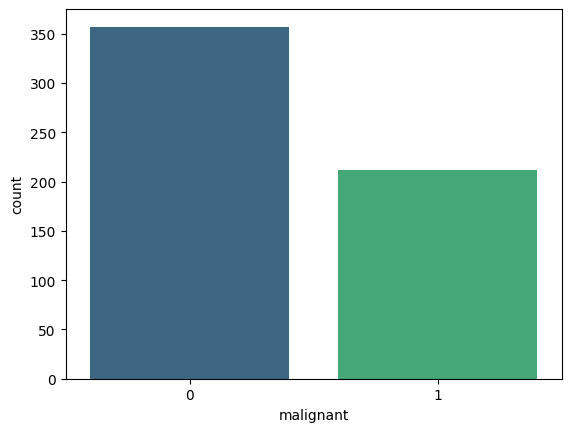

In [7]:
sns.countplot(x='malignant', hue='malignant', data=df, palette='viridis', legend=False)
plt.show()

<Axes: >

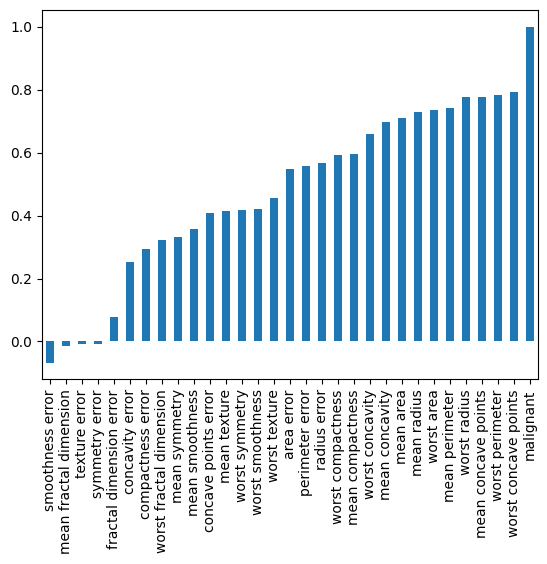

In [8]:
# correlation analysis, how is it correlated with dependent variable
df.corr()['malignant'].sort_values().plot(kind = "bar")

<Axes: >

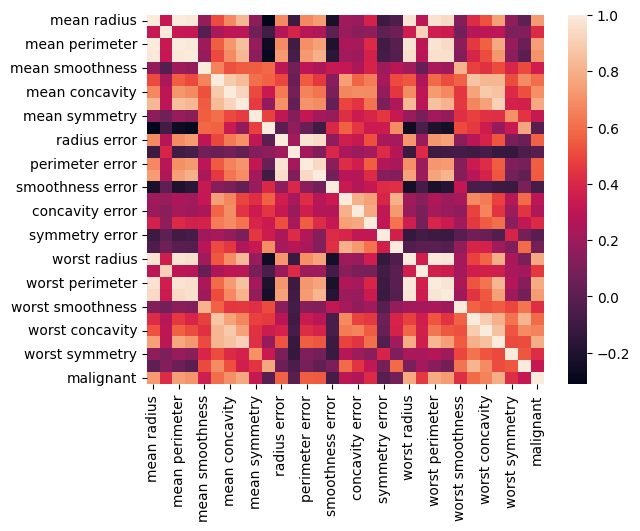

In [9]:
# correlation frame
sns.heatmap(df.corr())

In [10]:
x=df.drop('malignant', axis=1)
# x matrix all the data. except our dependent variable

y=df['malignant'].values

# ys is the dependent variable

In [11]:
x.shape
# dimension
# 569 rows and 30 columns

(569, 30)

In [12]:
y.shape

(569,)

In [13]:
y

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0,
       0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,

In [14]:
# for model buildling we need to split data into training set and test set
from sklearn.model_selection import train_test_split

In [15]:
x_train_full, x_test, y_train_full, y_test = train_test_split(x, y,
                                                    test_size=0.25,
                                                    random_state=101)

# hold out 20% of the training data as a validation set for early stopping,
# so the test set is only used once, for the final evaluation
x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full,
                                                  test_size=0.2,
                                                  random_state=101)

In [16]:
# Preprocessing - rescales each feature to the 0-1 range so no feature dominates because of its units
from sklearn.preprocessing import MinMaxScaler

In [17]:
scaler = MinMaxScaler()
# defining the scalar object

In [18]:
# fit the scaler on the training data only, then apply it to the other sets
x_train = scaler.fit_transform(x_train)

In [19]:
x_val = scaler.transform(x_val)
x_test = scaler.transform(x_test)

In [20]:
# finally start the deep learning part - artificial neural network libraries
# ANN libraries
# packages designed for deep learning

from tensorflow.keras.models import Sequential #sequential version of ANN
from tensorflow.keras.layers import Dense, Dropout

import tensorflow as tf
tf.keras.utils.set_random_seed(42)  # makes results reproducible

In [21]:
# building ANN
model = Sequential()
model.add(Dense(30, activation='relu')) #first neuronal layer, 30 is the number of nodes
model.add(Dense(15, activation='relu')) #second neuronal layer
model.add(Dense(1, activation='sigmoid')) #output layer
model.compile(loss='binary_crossentropy', optimizer='adam')

In [22]:
# model fitting - an epoch is one full pass through the training data
model.fit(x=x_train, y=y_train, epochs=600,
          validation_data=(x_val, y_val))

Epoch 1/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - loss: 0.6821 - val_loss: 0.6613
Epoch 2/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.6466 - val_loss: 0.6291
Epoch 3/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.6155 - val_loss: 0.5975
Epoch 4/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5830 - val_loss: 0.5662
Epoch 5/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.5499 - val_loss: 0.5340
Epoch 6/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.5150 - val_loss: 0.4996
Epoch 7/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4784 - val_loss: 0.4646
Epoch 8/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4408 - val_loss: 0.4278
Epoch 9/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.4022 - val_loss: 0.3915
Epoch 10/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3651 - val_loss: 0.3580
Epoch 11/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3317 - val_loss: 0.3284
Epoch 12/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - lo

<Axes: >

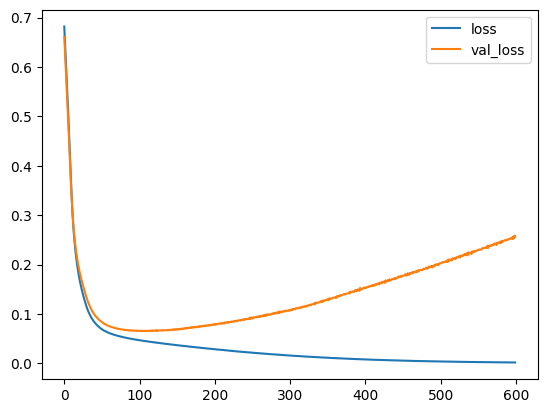

In [23]:
# Losses mean how the actual data of our dependent variable is different from the predicted data
# if the number is big there is a big discrepancy between what the data is saying versus what we predicted

losses = pd.DataFrame(model.history.history)
losses.plot()

In [24]:
# training loss (blue) keeps falling: the model fits the training data better and better
# validation loss rises after a point: the model is overfitting
# next: stop training at the right time and reduce complexity

In [25]:
from tensorflow.keras.callbacks import EarlyStopping
# stops training once validation loss stops improving, so the model doesn't overfit

In [26]:
early_stop = EarlyStopping(monitor='val_loss',
                           mode='min', verbose=1, patience=29)

In [27]:
# building ANN
model = Sequential()
model.add(Dense(30, activation='relu')) #first neuronal layer, 30 is the number of nodes
model.add(Dense(15, activation='relu')) #second neuronal layer
model.add(Dense(1, activation='sigmoid')) #output layer
model.compile(loss='binary_crossentropy', optimizer='adam')

In [28]:
model.fit(x=x_train, y=y_train, epochs=600,
          validation_data=(x_val, y_val),
          callbacks = [early_stop])

Epoch 1/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.7136 - val_loss: 0.6957
Epoch 2/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6863 - val_loss: 0.6747
Epoch 3/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6622 - val_loss: 0.6517
Epoch 4/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6366 - val_loss: 0.6257
Epoch 5/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6084 - val_loss: 0.5961
Epoch 6/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.5747 - val_loss: 0.5609
Epoch 7/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5330 - val_loss: 0.5141
Epoch 8/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.4843 - val_loss: 0.4666
Epoch 9/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.4365 - val_loss: 0.4207
Epoch 10/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3908 - val_loss: 0.3784
Epoch 11/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.3498 - val_loss: 0.3406
Epoch 12/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 

<Axes: >

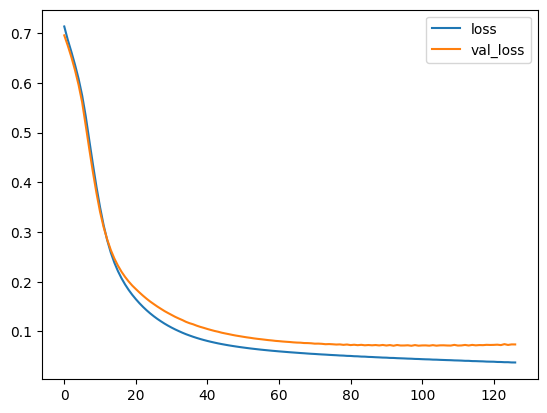

In [29]:
losses = pd.DataFrame(model.history.history)
losses.plot()

In [30]:
# this can also be used for reducing the complexity of your model
# building ANN
model = Sequential()
model.add(Dense(30, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(15, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))
model.compile(loss='binary_crossentropy', optimizer='adam')


In [31]:
early_stop = EarlyStopping(monitor='val_loss',
                           mode='min', verbose=1, patience=25)

In [32]:
model.fit(x=x_train, y=y_train, epochs=600,
          validation_data=(x_val, y_val),
          callbacks = [early_stop])

Epoch 1/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - loss: 0.6993 - val_loss: 0.6874
Epoch 2/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6958 - val_loss: 0.6755
Epoch 3/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6774 - val_loss: 0.6666
Epoch 4/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6625 - val_loss: 0.6562
Epoch 5/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.6503 - val_loss: 0.6442
Epoch 6/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.6421 - val_loss: 0.6247
Epoch 7/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 0.6288 - val_loss: 0.6048
Epoch 8/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.6194 - val_loss: 0.5824
Epoch 9/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.6178 - val_loss: 0.5629
Epoch 10/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5814 - val_loss: 0.5433
Epoch 11/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.5583 - val_loss: 0.5219
Epoch 12/600
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - 

<Axes: >

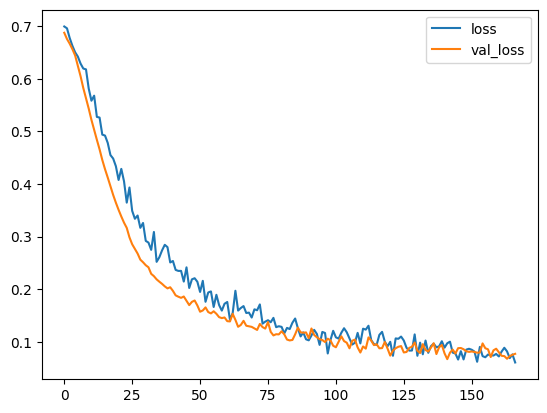

In [33]:
losses = pd.DataFrame(model.history.history)
losses.plot()

In [34]:
# with dropout + early stopping, training and validation loss stay close together

In [35]:
# finally, predict on the held-out test set; probability > 0.5 = malignant
# outputs the probability of whether it is malignant of benign

predictions = model.predict(x_test)
class_predictions = (predictions>0.5).astype('int')

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


In [36]:
class_predictions

array([[0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [1],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [1],
       [1],
       [1],
       [0],
       [0],
       [0],
       [0],
       [0],
       [1],
       [0],
       [1],
       [0],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [1],
       [1],
       [0],
       [1],
       [0],
       [0],
       [0],
       [1],
       [1],
       [0],
       [0],
       [1],
       [0],
       [0],
       [0],
       [0],
    

In [37]:
# final evaluation on the test set, which the model never saw during training
print(classification_report(y_test, class_predictions,
                            target_names=['Benign', 'Malignant']))

              precision    recall  f1-score   support

      Benign       0.99      0.99      0.99        88
   Malignant       0.98      0.98      0.98        55

    accuracy                           0.99       143
   macro avg       0.99      0.99      0.99       143
weighted avg       0.99      0.99      0.99       143



In [38]:
cm = confusion_matrix(y_test, class_predictions)

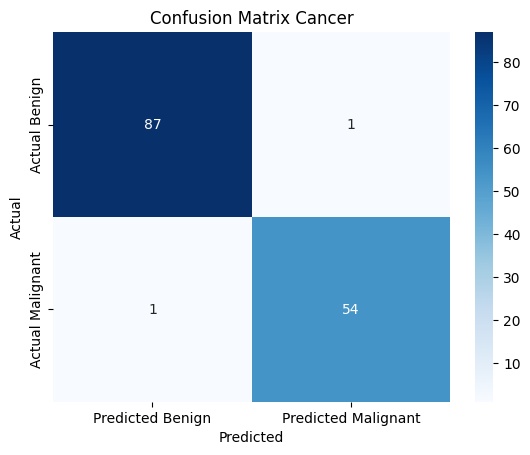

In [39]:
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
            xticklabels=["Predicted Benign", "Predicted Malignant"],
            yticklabels=["Actual Benign", "Actual Malignant"])
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.title("Confusion Matrix Cancer")
plt.show()